<a href="https://colab.research.google.com/github/bsyeol/26AI_project/blob/main/final/FDS_StageB_SIGMA_FDS_OfficialConfig_Seed0_Resume.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# FDS | SIGMA-FDS — official architecture configuration (Seed 0)

**목적:** SIGMA (AAAI 2025)의 공개 추천 모델 구조를 금융 이상거래 탐지용 시계열 인코더로 전용한다. 파라미터를 Transformer에 맞추기 위해 축소하지 않는다. 공식 config의 hidden=64, state=32, convolution=4, expand=2, layers=1, dropout=.2 유지. 실제 파라미터 수는 기록만 한다.

- 입력: 기존 3시간 단위 7개 집계 특징 → Linear(7,64) → 공식 SIGMA backbone → 마지막 과거 bin → Linear(64,32). 기존 7개 현재 거래 특징과 결합해 39개 입력으로 분류.
- 원본 GMambaBlock, SIGMALayers, FeedForward를 고정 GitHub commit에서 추출. 원본의 앞 45/50개 부분 역순을 최근 5개 bin(15h) 보존으로 일반화. Time2Vec/실제 거래 시간 간격 추가 없음.
- Mamba-1은 기존 Colab 환경 보존을 위해 순수 PyTorch FP32 selective scan 사용(공식 fused CUDA kernel 아님). 원본 및 변경 코드, config, MIT LICENSE, hash 저장.
- 동일 seed, 행 분할, 라벨 예산, epochs, learning rate, logical batch 256 유지. 메모리 절약을 위해 gradient accumulation (32행씩), 추론 batch 128. Dropout 난수 및 연산 순서는 달라질 수 있음.
- A100 권장. 기존 TabPFN 라이브러리 및 Colab Secrets TABPFN_TOKEN 필요. 1/2/7/14/30일 × 3분류기 = 15회, 자동 재개. 기존 GRU 및 Matched Transformer 읽기 전용, Large Transformer는 완결된 경우만 포함. 기존 축소 SIGMA와 별도 폴더.
- 결과는 예측 성능 비교이며 동일 파라미터 비교가 아님. 단일 seed, Test 미사용. GPU/전체 데이터 학습 미검증; 최대 길이 실제 microbatch 및 추론 batch smoke test 후 실행.
- Sources: https://github.com/ziwliu8/SIGMA ; https://arxiv.org/abs/2408.11451 ; https://github.com/state-spaces/mamba/tree/v1.1.4


In [1]:
# 1. Colab 설치: 기존 실험 버전 유지
import subprocess, sys
from importlib.metadata import version, PackageNotFoundError
packages={'tabpfn':'10.2.0','lightgbm':'4.7.0','pyarrow':'26.0.1'}
need=[]
for p,v in packages.items():
    try: installed=version(p)
    except PackageNotFoundError: installed=None
    if installed!=v: need.append(f'{p}=={v}')
if need: subprocess.check_call([sys.executable,'-m','pip','install','-q',*need])
# 이미 import된 패키지가 변경됐다면 런타임 재시작

In [2]:
# 2. 환경/설정 — GRU 원본 읽기 전용, SIGMA 별도 저장
from google.colab import drive, userdata
import os, json, gc, time, hashlib, inspect, platform, random, uuid
from pathlib import Path
from importlib.metadata import version
import numpy as np
import pandas as pd
import torch
from torch import nn
import lightgbm as lgb
from sklearn.model_selection import train_test_split
from sklearn.metrics import average_precision_score, precision_recall_curve, auc, roc_curve
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion
from tabpfn.finetuning.finetuned_classifier import FinetunedTabPFNClassifier
from tqdm.auto import tqdm
import matplotlib.pyplot as plt

drive.mount('/content/drive')
ROOT=Path('/content/drive/MyDrive/26-2_AI_project/processed/full')
SMOKE=False  # 기존 본 실험과 동일
RUN_DAYS=[1,2,7,14,30]
RUN_SEEDS=[0]
ALLOW_HARDWARE_CHANGE=True  # CPU/GPU 차이만 허용; 시간은 직접 비교 금지
RATIO='Original'  # 원본 비율 고정
WINDOW_DAYS=list(range(91))  # 0: baseline, 1~90: 매일 GRU
SEEDS=[0,1,2,3,4]
EVAL_NEG_FRAC=1.0  # 본 실험은 전수 평가; 빠른 예비 실험만 .2 (가중 지표)
TUNE_N=50000
TARGET_FPR=.001
REVIEW_TARGET_RECALL=.30  # 동일 Recall 비교용 목표: 30%, 필요 시 변경 (운영 기준 아님)
assert 0 < REVIEW_TARGET_RECALL <= 1
LATENCY_LIMIT=100.
LATENCY_REPEATS=20; LATENCY_WARMUPS=3
HIDDEN=32; GRU_EPOCHS=20; GRU_PATIENCE=3; GRU_LR=1e-3; GRU_BATCH=256
FT_EPOCHS=10; FT_LR=1e-5; FT_EPISODE=4096; FT_PATIENCE=3  # Original의 희소 양성 고려
FT_TRAIN_EST=1; FINAL_EST=4; FT_VAL_EST=1
PRED_BATCH=4096
MAX_TREES=2000; LGB_PATIENCE=50
THREADS=min(8,len(os.sched_getaffinity(0)))
MODELS=['LightGBM','TabPFN 3.5','TabPFN 3.5 FT']
assert torch.cuda.is_available(), 'GPU 런타임 필요'
assert hasattr(ModelVersion,'V3_5'), 'TabPFN 3.5 버전 필요'
# 라이브러리 버전별 API 불일치를 초기에 확인 (모델 자동 대체 금지)
ft_args=set(inspect.signature(FinetunedTabPFNClassifier).parameters)
required={'model_version','extra_classifier_kwargs','epochs','learning_rate','n_finetune_ctx_plus_query_samples','n_estimators_finetune','n_estimators_validation','n_estimators_final_inference','early_stopping_patience','eval_metric','random_state','use_activation_checkpointing','validation_split_ratio','device'}
assert required <= ft_args, f'Fine-tuning API 불일치: {required-ft_args}'
assert {'X_val','y_val'} <= set(inspect.signature(FinetunedTabPFNClassifier.fit).parameters), '외부 validation 지원 API 필요'
if not os.environ.get('TABPFN_TOKEN'):
    for k in ('TABPFN_TOKEN','TABPFN_API_KEY'):
        try: token=userdata.get(k)
        except Exception: continue
        if token: os.environ['TABPFN_TOKEN']=token; del token; break
assert os.environ.get('TABPFN_TOKEN'), 'Colab Secrets 인증 키 확인'
assert not SMOKE, '기존 GRU와 비교하는 본 예비 실험은 SMOKE=False 유지'
assert RATIO=='Original' and 0<EVAL_NEG_FRAC<=1
GRU_OUT=ROOT/'gru_tabpfn35_original_daily_v2_full'
MATCHED_OUT=ROOT/'transformer_matched_tabpfn35_original_seed0_v1_full'
LARGE_OUT=ROOT/'transformer_tabpfn35_original_seed0_v1_full'
OUT=ROOT/'sigma_fds_native_width_torchscan_tabpfn35_original_seed0_v1_full'
# Official config.yaml architecture (not parameter-matched).
SIGMA_DIM=64; SIGMA_STATE=32; SIGMA_CONV=4; SIGMA_EXPAND=2; SIGMA_LAYERS=1; SIGMA_DROPOUT=.2; KEEP_RECENT=5
# Memory-only change: accumulate gradients over 32-row microbatches to preserve logical batch 256.
SIGMA_MICRO_BATCH=32; SIGMA_INFER_BATCH=128
assert GRU_BATCH % SIGMA_MICRO_BATCH == 0
SIGMA_COMMIT="a3f63751503eca869338fc9c8b24a05fa128c6ef"
SIGMA_BACKEND="torch_associative_scan_fp32_v1"
assert SIGMA_DIM==64 and SIGMA_EXPAND==2 and SIGMA_LAYERS==1
assert HIDDEN == 32  # downstream embedding dimension
OUT.mkdir(parents=True,exist_ok=True)
(OUT/'runs').mkdir(exist_ok=True)
(OUT/'embeddings').mkdir(exist_ok=True)
S=json.loads((ROOT/'settings.json').read_text(encoding='utf-8'))
BASE=S['BASE_FEATURES']; CAT=S['CATEGORICAL_FEATURES']; LABEL=S['LABEL']; USER=S['USER']; CAT_IDX=[BASE.index(c) for c in CAT]
assert len(BASE)==7 and set(SEEDS)<=set(S['SEEDS'])
assert '거래금액_로그' in BASE and '매체구분' in CAT
DEVICE='cuda'; SESSION=uuid.uuid4().hex[:12]
ENV=dict(gpu=torch.cuda.get_device_name(0),vram=int(torch.cuda.get_device_properties(0).total_memory),cpu=next((x.split(':',1)[1].strip() for x in Path('/proc/cpuinfo').read_text().splitlines() if x.startswith('model name')),platform.processor()),threads=THREADS,python=platform.python_version(),cuda=torch.version.cuda,versions={p:version(p) for p in ['tabpfn','torch','lightgbm','numpy','pandas','scikit-learn','pyarrow']})
def sha(p):
    h=hashlib.sha256()
    with open(p,'rb') as f:
        for b in iter(lambda:f.read(2**20),b''): h.update(b)
    return h.hexdigest()
def write_json(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); tmp.write_text(json.dumps(obj,ensure_ascii=False,indent=2,allow_nan=False),encoding='utf-8'); os.replace(tmp,p)
def write_csv(p,obj):
    tmp=p.with_suffix(p.suffix+'.tmp'); obj.to_csv(tmp,index=False); os.replace(tmp,p)
def write_npz(path,**kw):
    tmp=path.with_suffix(path.suffix+'.tmp')
    with open(tmp,'wb') as f: np.savez_compressed(f,**kw)
    os.replace(tmp,path)
CONFIG=dict(data_sha=sha(ROOT/'full_v1.parquet'),settings_sha=sha(ROOT/'settings.json'),design='original_9996_shared_fit_80_tune_20_daily_v2',ratio=RATIO,days=WINDOW_DAYS,seeds=SEEDS,base=BASE,cat=CAT,label=LABEL,user=USER,eval_fraction=EVAL_NEG_FRAC,tune_n=TUNE_N,target_fpr=TARGET_FPR,latency_repeats=LATENCY_REPEATS,latency_warmups=LATENCY_WARMUPS,hidden=HIDDEN,gru_epochs=GRU_EPOCHS,gru_patience=GRU_PATIENCE,gru_lr=GRU_LR,gru_batch=GRU_BATCH,ft_epochs=FT_EPOCHS,ft_lr=FT_LR,ft_episode=FT_EPISODE,ft_patience=FT_PATIENCE,ft_train_est=FT_TRAIN_EST,ft_val_est=FT_VAL_EST,final_est=FINAL_EST,pred_batch=PRED_BATCH,max_trees=MAX_TREES,lgb_patience=LGB_PATIENCE,env=ENV,smoke=SMOKE)
cp=GRU_OUT/'config.json'
assert cp.exists(), f'기존 config.json 없음: {cp}. ROOT 경로를 확인하세요.'
OLD_CONFIG=json.loads(cp.read_text())
old_design={k:v for k,v in OLD_CONFIG.items() if k!='env'}
new_design={k:v for k,v in CONFIG.items() if k!='env'}
diff=[k for k in sorted(old_design.keys() | new_design.keys()) if old_design.get(k)!=new_design.get(k)]
assert not diff, f'데이터/실험 설정 불일치: {diff}. 기존 config를 삭제하지 마세요.'
old_env=OLD_CONFIG['env']
hw_keys={'gpu','vram','cpu','threads'}
software_diff={k:(old_env.get(k),ENV.get(k)) for k in sorted(old_env.keys() | ENV.keys()) if k not in hw_keys and old_env.get(k)!=ENV.get(k)}
assert not software_diff, f'소프트웨어 환경 불일치: {software_diff}. 기존 config 버전으로 맞춘 뒤 재실행하세요.'
hardware_diff={k:(old_env.get(k),ENV.get(k)) for k in sorted(hw_keys) if old_env.get(k)!=ENV.get(k)}
assert ALLOW_HARDWARE_CHANGE or not hardware_diff, f'하드웨어 불일치: {hardware_diff}'
if hardware_diff: print('주의: 하드웨어 변경:',hardware_diff,'학습/추론 시간은 기존 세션과 직접 비교하지 마세요.')
assert set(RUN_DAYS)<=set(WINDOW_DAYS) and all(d>0 for d in RUN_DAYS)
assert set(RUN_SEEDS)<=set(SEEDS)
# Official source snapshot, preserved in new output folder. Fail closed on unavailable source.
import urllib.request, ast
PROV=OUT/'provenance'; PROV.mkdir(exist_ok=True)
for relative,name in [('model/gated_mamba.py','gated_mamba_original.py'),('LICENSE','SIGMA_LICENSE'),('model/config.yaml','config_original.yaml')]:
    dst=PROV/name
    if not dst.exists():
        url=f'https://raw.githubusercontent.com/ziwliu8/SIGMA/{SIGMA_COMMIT}/{relative}'
        with urllib.request.urlopen(url,timeout=60) as response: payload=response.read()
        assert payload, f'Empty upstream source: {url}'
        tmp=dst.with_suffix(dst.suffix+'.tmp'); tmp.write_bytes(payload); os.replace(tmp,dst)
assert 'MIT License' in (PROV/'SIGMA_LICENSE').read_text(), 'Upstream license needs review'
# Verify pinned upstream YAML against official architecture; no YAML dependency needed.
import re
original_yaml=(PROV/'config_original.yaml').read_text(encoding='utf-8')
for key, expected in {'hidden_size':SIGMA_DIM,'d_state':SIGMA_STATE,'d_conv':SIGMA_CONV,'expand':SIGMA_EXPAND,'num_layers':SIGMA_LAYERS,'dropout_prob':SIGMA_DROPOUT}.items():
    match=re.search(r'^\s*'+re.escape(key)+r'\s*:\s*([0-9.]+)',original_yaml,flags=re.M)
    assert match and float(match.group(1))==expected, f'Official config mismatch: {key}'
source=(PROV/'gated_mamba_original.py').read_text(encoding='utf-8')
parsed=ast.parse(source)
classes={node.name:ast.get_source_segment(source,node) for node in parsed.body if isinstance(node,ast.ClassDef)}
assert {'GMambaBlock','SIGMALayers','FeedForward'}<=classes.keys()
backbone='\n\n'.join(classes[k] for k in ['GMambaBlock','SIGMALayers','FeedForward'])
old='flipped_input[:, :45, :] = input_tensor[:, :45, :].flip(dims=[1])'
assert backbone.count(old)==1, 'Unexpected upstream partial flip; review before running'
backbone=backbone.replace(old,'n = max(0, input_tensor.shape[1] - KEEP_RECENT)\n        flipped_input[:, :n, :] = input_tensor[:, :n, :].flip(dims=[1])')
# Preserve source computation, including raw mixing weights and h1 in the second sigmoid gate.
assert 'self.combining_weights[2]' in backbone and 'self.selective_gate_sig(h1)' in backbone
ast.parse(backbone)
(PROV/'backbone_adapted.py').write_text('# Requires torch, nn, F, Mamba and KEEP_RECENT from notebook. See SIGMA_LICENSE.\n'+backbone,encoding='utf-8')
SIGMA_CONFIG=dict(source_config_sha=sha(cp),source_rows_sha=sha(GRU_OUT/'rows.npz'),design='sigma_fds_official_config_d64_state32_expand2_recent5_v1',upstream_commit=SIGMA_COMMIT,upstream_source_sha=sha(PROV/'gated_mamba_original.py'),adapted_sha=sha(PROV/'backbone_adapted.py'),backend=SIGMA_BACKEND,dim=SIGMA_DIM,d_state=SIGMA_STATE,d_conv=SIGMA_CONV,expand=SIGMA_EXPAND,layers=SIGMA_LAYERS,dropout=SIGMA_DROPOUT,keep_recent=KEEP_RECENT,parameter_policy="official_architecture_not_matched",micro_batch=SIGMA_MICRO_BATCH,infer_batch=SIGMA_INFER_BATCH,output_dim=HIDDEN,days=RUN_DAYS,seeds=RUN_SEEDS,max_epochs=GRU_EPOCHS,patience=GRU_PATIENCE,lr=GRU_LR,batch=GRU_BATCH,review_target_recall=REVIEW_TARGET_RECALL,source_design=old_design,software={k:v for k,v in ENV.items() if k not in hw_keys})
sigma_cp=OUT/'config.json'
if sigma_cp.exists(): assert json.loads(sigma_cp.read_text())==SIGMA_CONFIG, 'SIGMA 설정 변경: 새 OUT 폴더 사용'
else: write_json(sigma_cp,SIGMA_CONFIG)
PILOT=OUT/'pilot_seed0'; PILOT.mkdir(exist_ok=True)
(OUT/'sessions').mkdir(exist_ok=True)
write_json(OUT/'sessions'/f'{SESSION}.json',dict(session=SESSION,env=ENV,hardware_diff=hardware_diff,run_days=RUN_DAYS,run_seeds=RUN_SEEDS,original_config=OLD_CONFIG))
print('현재 환경:',ENV)
print('GRU 원본:',GRU_OUT); print('SIGMA 결과:',OUT)
print('예비 실험:',RUN_DAYS,RUN_SEEDS,'최대',len(RUN_DAYS)*len(RUN_SEEDS)*len(MODELS),'회')


Mounted at /content/drive
주의: 하드웨어 변경: {'cpu': ('Intel(R) Xeon(R) CPU @ 2.00GHz', 'Intel(R) Xeon(R) CPU @ 2.20GHz'), 'gpu': ('Tesla T4', 'NVIDIA L4'), 'vram': (15637086208, 23659151360)} 학습/추론 시간은 기존 세션과 직접 비교하지 마세요.
현재 환경: {'gpu': 'NVIDIA L4', 'vram': 23659151360, 'cpu': 'Intel(R) Xeon(R) CPU @ 2.20GHz', 'threads': 8, 'python': '3.13.16', 'cuda': '13.0', 'versions': {'tabpfn': '10.2.0', 'torch': '2.14.1+cu130', 'lightgbm': '4.7.0', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1', 'pyarrow': '26.0.1'}}
GRU 원본: /content/drive/MyDrive/26-2_AI_project/processed/full/gru_tabpfn35_original_daily_v2_full
SIGMA 결과: /content/drive/MyDrive/26-2_AI_project/processed/full/sigma_fds_native_width_torchscan_tabpfn35_original_seed0_v1_full
예비 실험: [1, 2, 7, 14, 30] [0] 최대 15 회


In [3]:
# 3. 데이터 및 라벨 예산 분리
cols=list(dict.fromkeys(BASE+[LABEL,USER,'입금계좌일련번호','bin_id','split','date']))
df=pd.read_parquet(ROOT/'full_v1.parquet',columns=cols)
assert df.index.equals(pd.RangeIndex(len(df))) and not df[cols].isna().any().any()
y=df[LABEL].to_numpy(np.int8); bins=df['bin_id'].to_numpy(np.int64); split=df['split'].to_numpy()
assert set(np.unique(y))=={0,1}
train=np.flatnonzero(split=='train'); val=np.flatnonzero(split=='val')
assert bins[train].max()<bins[val].min(), '시간 분할 확인'
# 기존 Original V2와 동일 날짜 경계
dates=pd.to_datetime(df['date']).to_numpy()
val=val[np.argsort(dates[val],kind='stable')]; assert len(val)>TUNE_N
cut=np.searchsorted(dates[val],dates[val[TUNE_N-1]],side='right')
cal=val[:cut]; pool=val[cut:]
neg=pool[y[pool]==0]; pos=pool[y[pool]==1]
rng=np.random.default_rng(2026); sampled=rng.choice(neg,max(1,int(len(neg)*EVAL_NEG_FRAC)),replace=False)
ev=np.sort(np.r_[pos,sampled]); frac=len(sampled)/len(neg); weights=np.where(y[ev]==1,1.,1./frac)
# Smoke calibration만 줄임. 본 실험에서는 전수 calibration.
if SMOKE:
    cal=np.sort(np.r_[cal[y[cal]==1],rng.choice(cal[y[cal]==0],min(2000,int((y[cal]==0).sum())),replace=False)])
cal_weights=np.ones(len(cal))
if SMOKE: cal_weights=np.where(y[cal]==1,1.,(y[val[:cut]]==0).sum()/(y[cal]==0).sum())
assert set(y[ev])==set(y[cal])=={0,1}
P={}
rate=float(y[train].mean()); npos=round(9996*rate)
assert npos==38, f'기존 Original 비율과 다름: {rate:.6%}'
print(f'Train original fraud rate: {rate:.6%}; label budget: 9996 ({npos} positives)')
for seed in SEEDS:
    rng=np.random.default_rng(seed)
    rows=np.sort(np.r_[rng.choice(train[y[train]==1],npos,replace=False),rng.choice(train[y[train]==0],9996-npos,replace=False)])
    assert len(rows)==9996 and len(np.unique(rows))==9996 and (split[rows]=='train').all() and y[rows].sum()==npos
    fit_rows,tune=train_test_split(rows,test_size=.2,random_state=seed,stratify=y[rows])
    fit_rows=np.sort(fit_rows); tune=np.sort(tune)
    # 같은 fit 행을 인코더 지도학습 및 분류기 학습에 제공; tune과 평가 분리.
    P[seed]=dict(enc=fit_rows,clf=fit_rows,tune=tune)
    assert not np.intersect1d(fit_rows,tune).size and len(fit_rows)+len(tune)==9996
    assert set(y[fit_rows])==set(y[tune])=={0,1}
    print(seed,{k:(len(v),int(y[v].sum()),float(y[v].mean())) for k,v in P[seed].items()})
# 기존 데이터 분할과 정확히 일치하는지 확인. 원본 파일 덮어쓰기 금지.
expected_rows=dict(cal=cal,eval=ev,cal_weights=cal_weights,eval_weights=weights,**{f'{k}_{s}':v for s,d in P.items() for k,v in d.items()})
assert (GRU_OUT/'rows.npz').exists(), '기존 rows.npz 없음: 결과 폴더 확인'
with np.load(GRU_OUT/'rows.npz',allow_pickle=False) as saved:
    assert set(saved.files)==set(expected_rows), '기존 데이터 분할 키 불일치'
    for key,value in expected_rows.items():
        assert np.array_equal(saved[key],value), f'기존 데이터 분할 불일치: {key}'
del expected_rows
print('기존 rows.npz 검증 완료')
print('Calibration',len(cal),'Evaluation',len(ev),'positive',int(y[ev].sum()),'negative fraction',frac)

Train original fraud rate: 0.375697%; label budget: 9996 (38 positives)
0 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
1 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
2 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
3 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
4 {'enc': (7996, 30, 0.0037518759379689846), 'clf': (7996, 30, 0.0037518759379689846), 'tune': (2000, 8, 0.004)}
기존 rows.npz 검증 완료
Calibration 50926 Evaluation 305365 positive 1423 negative fraction 1.0


In [4]:
# 4. 계좌별 3시간 집계 인덱스. 전체 dense 시퀀스를 저장하지 않는다.
# 원본 파일의 log1p(거래금액)를 역변환해 총액/평균/최대액을 구하고 log1p 적용.
t=bins-bins.min(); u=pd.factorize(df[USER],sort=False)[0].astype(np.int64)
B=int(t.max())+1
assert (u>=0).all() and (t>=0).all() and int(u.max())*B+B<np.iinfo(np.int64).max
key=u*B+t
# Test 거래도 과거 조회의 입력이 되지 않도록 사전 제거 (현재 평가 대상은 val까지)
known=np.flatnonzero(np.isin(split,['train','val']))
raw_amt=np.expm1(df['거래금액_로그'].to_numpy(np.float64)[known]); assert np.isfinite(raw_amt).all() and (raw_amt>=0).all()
a=pd.DataFrame(dict(key=key[known],amount=raw_amt,recv=df['입금계좌일련번호'].to_numpy()[known],media=df['매체구분'].to_numpy()[known]))
g=a.groupby('key',sort=True).agg(count=('amount','size'),total=('amount','sum'),mean=('amount','mean'),max=('amount','max'),recv=('recv','nunique'),media=('media','nunique'))
K=g.index.to_numpy(np.int64); V=np.log1p(g.to_numpy(np.float64)).astype(np.float32)
assert len(K)>0 and np.isfinite(V).all() and np.all(K[1:]>K[:-1])
static=df[BASE].copy()
for c in CAT: static[c]=static[c].astype('int32')
assert np.isfinite(static.to_numpy(np.float64)).all()
del a,g,raw_amt,df; gc.collect()
# Gather returns [batch, 8*days, 7]. 마지막 채널=데이터 관측 여부.
# 현재 bin 미포함, 음수 시간은 padding, 다른 계좌로 넘어가는 것 방지.
def gather(rows,days):
    rows=np.asarray(rows,dtype=np.int64); L=8*days
    assert L>0
    tt=t[rows,None]-np.arange(L,0,-1,dtype=np.int64)[None,:]
    observed=tt>=0
    keys=u[rows,None]*B+np.maximum(tt,0)
    ix=np.searchsorted(K,keys); safe=np.minimum(ix,len(K)-1)
    hit=observed & (ix<len(K)) & (K[safe]==keys)
    z=np.zeros((len(rows),L,7),np.float32)
    z[hit,:6]=V[safe[hit]]; z[:,:,6]=observed
    return z
# 작은 self-check: 조회된 모든 key는 해당 계좌의 과거 bin.
r=P[SEEDS[0]]['enc'][:4]
assert gather(r,1).shape==(len(r),8,7) and gather(r,90).shape==(len(r),720,7)
assert np.array_equal(gather(r,90)[:,-8:],gather(r,1))
print('계좌×bin 고유 집계:',len(K),'history gather 확인 완료')

계좌×bin 고유 집계: 2958408 history gather 확인 완료


In [5]:
# 5a. Mamba-1 selective SSM, portable PyTorch implementation (not fused CUDA kernel).
# Reference: https://github.com/state-spaces/mamba/blob/v1.1.4/mamba_ssm/modules/mamba_simple.py
import math
import torch.nn.functional as F

def affine_scan(a,b,chunk=32):
    # a,b: [B,L,D,N]; h_t = a_t*h_(t-1)+b_t, h_0=0.
    # Associative composition in each chunk, then propagate incoming state.
    state=torch.zeros_like(b[:,0]); pieces=[]
    for start in range(0,a.shape[1],chunk):
        aa=a[:,start:start+chunk]; bb=b[:,start:start+chunk]
        step=1
        while step<aa.shape[1]:
            aa,bb=(torch.cat((aa[:,:step],aa[:,step:]*aa[:,:-step]),dim=1),
                   torch.cat((bb[:,:step],bb[:,step:]+aa[:,step:]*bb[:,:-step]),dim=1))
            step*=2
        hh=bb+aa*state[:,None]; pieces.append(hh); state=hh[:,-1]
    return torch.cat(pieces,dim=1)

class Mamba(nn.Module):
    # Compatible constructor/forward for upstream SIGMA's Mamba-1 calls only.
    def __init__(self,d_model,d_state=16,d_conv=4,expand=2):
        super().__init__(); self.d_model=d_model; self.d_state=d_state
        self.d_inner=int(d_model*expand); self.dt_rank=math.ceil(d_model/16)
        d=self.d_inner; r=self.dt_rank
        self.in_proj=nn.Linear(d_model,2*d,bias=False)
        self.conv1d=nn.Conv1d(d,d,d_conv,groups=d,padding=d_conv-1,bias=True)
        self.x_proj=nn.Linear(d,r+2*d_state,bias=False)
        self.dt_proj=nn.Linear(r,d,bias=True)
        nn.init.uniform_(self.dt_proj.weight,-r**-.5,r**-.5)
        dt=torch.exp(torch.rand(d)*(math.log(.1)-math.log(.001))+math.log(.001))
        with torch.no_grad(): self.dt_proj.bias.copy_(dt+torch.log(-torch.expm1(-dt)))
        self.A_log=nn.Parameter(torch.arange(1,d_state+1,dtype=torch.float32).log().repeat(d,1))
        self.D=nn.Parameter(torch.ones(d))
        self.out_proj=nn.Linear(d,d_model,bias=False)
    def forward(self,x):
        L=x.shape[1]; u,z=self.in_proj(x).chunk(2,dim=-1)
        u=F.silu(self.conv1d(u.transpose(1,2))[...,:L].transpose(1,2))
        delta,B,C=self.x_proj(u).split([self.dt_rank,self.d_state,self.d_state],dim=-1)
        delta=F.softplus(self.dt_proj(delta).float())
        A=-self.A_log.float().exp()
        a=torch.exp(delta[...,None]*A)
        b=(delta*u.float())[...,None]*B.float()[:,:,None,:]
        h=affine_scan(a,b)
        y=(h*C.float()[:,:,None,:]).sum(-1)+self.D.float()*u.float()
        return self.out_proj((y*F.silu(z.float())).to(x.dtype))

# Load only audited upstream classes, not RecBole or training scripts.
exec(compile(backbone,'SIGMA_GMamba_adapted.py','exec'),globals())
class Encoder(nn.Module):
    def __init__(self):
        super().__init__()
        self.input_proj=nn.Linear(7,SIGMA_DIM)
        self.dropout=nn.Dropout(SIGMA_DROPOUT)
        self.LayerNorm=nn.LayerNorm(SIGMA_DIM,eps=1e-12)
        self.mamba_layers=nn.ModuleList([SIGMALayers(d_model=SIGMA_DIM,d_state=SIGMA_STATE,d_conv=SIGMA_CONV,expand=SIGMA_EXPAND,dropout=SIGMA_DROPOUT,num_layers=SIGMA_LAYERS) for _ in range(SIGMA_LAYERS)])
        self.output_proj=nn.Linear(SIGMA_DIM,HIDDEN); self.head=nn.Linear(HIDDEN,1)
        # Match upstream SIGMA outer initialization, including dt projection override.
        self.apply(self.init_weights)
    @staticmethod
    def init_weights(module):
        if isinstance(module,nn.Linear):
            nn.init.normal_(module.weight,mean=0.,std=.02)
            if module.bias is not None: nn.init.zeros_(module.bias)
        elif isinstance(module,nn.LayerNorm):
            nn.init.ones_(module.weight); nn.init.zeros_(module.bias)
    def encode(self,x):
        x=self.LayerNorm(self.dropout(self.input_proj(x)))
        for layer in self.mamba_layers: x=layer(x)
        return self.output_proj(x[:,-1,:])
    def forward(self,x): return self.head(self.encode(x)).squeeze(-1)

SIGMA_PARAMS=sum(p.numel() for p in Encoder().parameters())
# Count for transparency, not as a target. Persist count with source config.
assert SIGMA_PARAMS > 0
print(f'SIGMA-FDS trainable parameters (including binary head): {SIGMA_PARAMS:,}')
write_json(PROV/'parameter_count.json',dict(total=SIGMA_PARAMS,backbone=sum(p.numel() for p in Encoder().mamba_layers.parameters()),policy='official architecture; not matched'))
# Verify associative scan against serial recurrence, including gradients; then GPU smoke test.
def smoke_test():
    a=torch.rand(2,65,3,4,device=DEVICE,requires_grad=True); b=torch.randn_like(a,requires_grad=True)
    out=affine_scan(a,b); h=torch.zeros_like(b[:,0]); ref=[]
    for t in range(a.shape[1]): h=a[:,t]*h+b[:,t]; ref.append(h)
    ref=torch.stack(ref,dim=1); torch.testing.assert_close(out,ref,rtol=2e-5,atol=2e-6)
    go=torch.autograd.grad(out.square().mean(),(a,b)); gr=torch.autograd.grad(ref.square().mean(),(a,b))
    for u,v in zip(go,gr): torch.testing.assert_close(u,v,rtol=5e-4,atol=2e-6)
    model=Encoder().to(DEVICE)
    for d in RUN_DAYS:
        model.zero_grad(set_to_none=True); x=torch.randn(2,d*8,7,device=DEVICE); p=model(x)
        assert p.shape==(2,) and torch.isfinite(p).all(); p.square().mean().backward()
        assert all(v.grad is not None and torch.isfinite(v.grad).all() for v in model.parameters())
        model.eval()
        with torch.no_grad(): assert model.encode(x).shape==(2,32)
        model.train()
    # Test actual largest window with the selected microbatch sizes before financial training.
    if DEVICE == 'cuda':
        model.zero_grad(set_to_none=True); torch.cuda.reset_peak_memory_stats()
        x=torch.randn(SIGMA_MICRO_BATCH,max(RUN_DAYS)*8,7,device=DEVICE)
        p=model(x); p.square().mean().backward()
        assert torch.isfinite(p).all() and all(v.grad is not None and torch.isfinite(v.grad).all() for v in model.parameters())
        print('Training smoke peak allocated GiB:',round(torch.cuda.max_memory_allocated()/2**30,2))
        del x,p; model.zero_grad(set_to_none=True); model.eval(); torch.cuda.empty_cache()
        torch.cuda.reset_peak_memory_stats()
        with torch.no_grad():
            x=torch.randn(SIGMA_INFER_BATCH,max(RUN_DAYS)*8,7,device=DEVICE)
            z=model.encode(x); assert z.shape==(SIGMA_INFER_BATCH,32) and torch.isfinite(z).all()
        print('Inference smoke peak allocated GiB:',round(torch.cuda.max_memory_allocated()/2**30,2)); del x,z
    del model; torch.cuda.empty_cache(); print(f'{DEVICE} scan/shape/gradient smoke test passed')
smoke_test()

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark=False; torch.backends.cudnn.deterministic=True
# log1p 변환 후 scale은 SIGMA 학습 행에서만 계산; 0은 계속 0.
def scale_for(rows,days):
    ss=np.zeros(6,np.float64); n=0
    for i in range(0,len(rows),GRU_BATCH):
        z=gather(rows[i:i+GRU_BATCH],days); ss+=(z[:,:,:6].astype(np.float64)**2).sum(axis=(0,1)); n+=int(z[:,:,6].sum())
    return np.maximum(np.sqrt(ss/max(n,1)),1.).astype(np.float32)
def tensor(rows,days,scale):
    z=gather(rows,days); z[:,:,:6]/=scale
    return torch.from_numpy(z).to(DEVICE)
@torch.no_grad()
def encode_rows(model,rows,days,scale):
    model.eval(); z=np.empty((len(rows),HIDDEN),np.float32)
    for i in tqdm(range(0,len(rows),SIGMA_INFER_BATCH),desc=f'SIGMA encode {days}d ({len(rows):,} rows)',leave=False):
        z[i:i+SIGMA_INFER_BATCH]=model.encode(tensor(rows[i:i+SIGMA_INFER_BATCH],days,scale)).cpu().numpy()
    return z
@torch.no_grad()
def head_pred(model,rows,days,scale):
    model.eval(); ps=[]
    for i in range(0,len(rows),SIGMA_INFER_BATCH): ps.append(model(tensor(rows[i:i+SIGMA_INFER_BATCH],days,scale)).sigmoid().cpu().numpy())
    return np.concatenate(ps)
# GRU_* 설정명은 원본 비교 조건 보존을 위해 그대로 사용한다.
def train_sigma(seed,days):
    set_seed(seed); enc=P[seed]['enc']; tune=P[seed]['tune']; scale=scale_for(enc,days)
    model=Encoder().to(DEVICE); opt=torch.optim.AdamW(model.parameters(),lr=GRU_LR)
    pw=float((y[enc]==0).sum()/(y[enc]==1).sum()); lossfn=nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw,device=DEVICE))
    best=-np.inf; state=None; wait=0; history=[]; rng=np.random.default_rng(seed)
    for epoch in range(GRU_EPOCHS):
        model.train(); order=rng.permutation(enc); loss_sum=0.
        for i in range(0,len(order),GRU_BATCH):
            b=order[i:i+GRU_BATCH]; opt.zero_grad(set_to_none=True)
            # Preserve one optimizer update per logical batch; normalize by actual row count.
            for j in range(0,len(b),SIGMA_MICRO_BATCH):
                mb=b[j:j+SIGMA_MICRO_BATCH]
                logits=model(tensor(mb,days,scale)); loss=lossfn(logits,torch.as_tensor(y[mb],device=DEVICE,dtype=torch.float32))
                assert torch.isfinite(loss), "Nonfinite SIGMA loss"
                (loss*(len(mb)/len(b))).backward(); loss_sum+=float(loss.detach())*len(mb)
            nn.utils.clip_grad_norm_(model.parameters(),1.); opt.step()
        ap=float(average_precision_score(y[tune],head_pred(model,tune,days,scale)))
        fit_ap=float(average_precision_score(y[enc],head_pred(model,enc,days,scale)))
        history.append(dict(epoch=epoch+1,loss=loss_sum/len(enc),tune_AP=ap,fit_AP=fit_ap))
        print(f'SIGMA d={days} seed={seed} epoch={epoch+1}/{GRU_EPOCHS} loss={loss_sum/len(enc):.5f} tune_AP={ap:.5f} fit_AP={fit_ap:.5f}',flush=True)
        if ap>best+1e-6:
            best=ap; state={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}; wait=0
        else: wait+=1
        if wait>=GRU_PATIENCE: break
    assert state is not None
    model.load_state_dict(state); model.eval(); model.requires_grad_(False)
    return model,scale,history

def cleanup(): gc.collect(); torch.cuda.empty_cache()
def timed(fn):
    torch.cuda.synchronize(); start=time.perf_counter_ns(); ans=fn(); torch.cuda.synchronize(); return ans,(time.perf_counter_ns()-start)/1e9

def make_table(rows,z=None):
    x=static.iloc[rows].reset_index(drop=True).copy()
    if z is not None:
        x=pd.concat([x,pd.DataFrame(z,columns=[f'sigma_{i:02d}' for i in range(HIDDEN)])],axis=1)
    return x

def get_encoder(seed,days):
    if days==0: return None,None,0.,0.,None
    prefix=OUT/'embeddings'/f'd{days}_s{seed}'
    path=prefix.with_suffix('.pt'); meta=prefix.with_suffix('.json')
    if path.exists() and meta.exists():
        obj=torch.load(path,map_location='cpu',weights_only=True); model=Encoder().to(DEVICE); model.load_state_dict(obj['state']); model.eval(); model.requires_grad_(False)
        info=json.loads(meta.read_text()); print(f'SIGMA d={days} seed={seed}: 저장 체크포인트 재사용',flush=True); return model,obj['scale'].numpy(),info['sigma_train_sec'],info['sigma_best_AP'],prefix
    (model,scale,history),sec=timed(lambda:train_sigma(seed,days))
    tmp=path.with_suffix('.tmp'); torch.save(dict(state={k:v.cpu() for k,v in model.state_dict().items()},scale=torch.from_numpy(scale)),tmp); os.replace(tmp,path)
    write_json(meta,dict(sigma_train_sec=sec,sigma_best_AP=max(h['tune_AP'] for h in history),history=history,parameters=sum(p.numel() for p in model.parameters()),session=SESSION,env=ENV))
    return model,scale,sec,max(h['tune_AP'] for h in history),prefix

def get_tables(seed,days,model,scale,prefix):
    rows={**{k:P[seed][k] for k in ['clf','tune']},'cal':cal,'ev':ev}
    if days==0: return {k:make_table(v) for k,v in rows.items()},0.
    # 여러 기간/seed 임베딩 전수 저장 시 수십 GB 이상 소모될 수 있음.
    # encoder checkpoint만 보존하고 필요 시 임베딩 재생성.
    z,sec=timed(lambda:{k:encode_rows(model,v,days,scale) for k,v in rows.items()})
    return {k:make_table(v,z[k]) for k,v in rows.items()},sec


SIGMA-FDS trainable parameters (including binary head): 132,612
Training smoke peak allocated GiB: 3.32
Inference smoke peak allocated GiB: 2.07
cuda scan/shape/gradient smoke test passed


In [6]:
# 6. 세 분류기: LGBM tuning, TabPFN 기본, TabPFN 실제 fine-tuning
# FT의 내부 validation에는 분류기 학습 행과 겹치지 않는 tune 사용.
# 실제 버전의 wrapper 최종 inference fit mode는 결과에 기록.
LGB_GRID=[dict(num_leaves=7,min_child_samples=2,learning_rate=.05),dict(num_leaves=15,min_child_samples=5,learning_rate=.05),dict(num_leaves=31,min_child_samples=10,learning_rate=.05),dict(num_leaves=31,min_child_samples=20,learning_rate=.1)]
def make_lgb(seed,trees,params):
    return lgb.LGBMClassifier(n_estimators=trees,objective='binary',metric='average_precision',random_state=seed,n_jobs=THREADS,verbosity=-1,deterministic=True,force_col_wise=True,device_type='cpu',**params)
def fit_lgb(X,yt,Xv,yv,seed):
    candidates=[]
    for p in LGB_GRID:
        m=make_lgb(seed,MAX_TREES,p)
        m.fit(X,yt,categorical_feature=CAT,eval_set=[(Xv,yv)],callbacks=[lgb.early_stopping(LGB_PATIENCE,first_metric_only=True,verbose=False)])
        candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.best_iteration_),p))
    p=LGB_GRID[-1]; m=make_lgb(seed,300,p); m.fit(X,yt,categorical_feature=CAT)
    candidates.append((float(average_precision_score(yv,m.predict_proba(Xv)[:,1])),int(m.booster_.num_trees()),p))
    ap,trees,p=max(candidates,key=lambda a:(a[0],-a[1])); m=make_lgb(seed,max(1,trees),p); m.fit(X,yt,categorical_feature=CAT)
    return m,dict(trees=int(m.booster_.num_trees()),selected_tune_AP=ap,params=p)
def base_model(seed):
    return TabPFNClassifier.create_default_for_version(ModelVersion.V3_5,device=DEVICE,random_state=seed,n_estimators=FINAL_EST,categorical_features_indices=CAT_IDX,fit_mode='fit_preprocessors')
def ft_model(seed):
    return FinetunedTabPFNClassifier(model_version=ModelVersion.V3_5,device=DEVICE,epochs=FT_EPOCHS,learning_rate=FT_LR,validation_split_ratio=None,n_finetune_ctx_plus_query_samples=FT_EPISODE,early_stopping_patience=FT_PATIENCE,n_estimators_finetune=FT_TRAIN_EST,n_estimators_validation=FT_VAL_EST,n_estimators_final_inference=FINAL_EST,random_state=seed,use_activation_checkpointing=True,eval_metric='roc_auc',extra_classifier_kwargs={'categorical_features_indices':CAT_IDX})
def fit_classifier(name,seed,tables):
    set_seed(seed); X=tables['clf']; yt=y[P[seed]['clf']]; Xv=tables['tune']; yv=y[P[seed]['tune']]
    if name=='LightGBM': return fit_lgb(X,yt,Xv,yv,seed)
    if name=='TabPFN 3.5':
        m=base_model(seed); m.fit(X,yt); return m,dict(fit_mode=str(m.fit_mode),estimators=FINAL_EST)
    m=ft_model(seed)
    m.fit(X,yt,X_val=Xv,y_val=yv)
    # wrapper's public predict_proba uses its final inference classifier.
    final=getattr(m,'finetuned_inference_classifier_',None)
    assert final is not None, 'Fine-tuned inference classifier missing'
    return m,dict(fit_mode=str(getattr(final,'fit_mode','unknown')),estimators=FINAL_EST,ft_epochs_max=FT_EPOCHS,ft_episode=FT_EPISODE)

def predict(m,X):
    out=np.empty(len(X),np.float64)
    for i in tqdm(range(0,len(X),PRED_BATCH),desc=f'Prediction ({len(X):,} rows)',leave=False):
        q=np.asarray(m.predict_proba(X.iloc[i:i+PRED_BATCH])); assert q.shape[1]==2
        out[i:i+PRED_BATCH]=q[:,1]
    assert np.isfinite(out).all(); return out

def operating_point(yt,p,w):
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    ii=np.flatnonzero(fpr<=TARGET_FPR); j=ii[np.argmax(tpr[ii])]
    return float(tpr[j]),float(fpr[j]),float(th[j])
def review_metrics(p,pc,eval_point=None,cal_point=None):
    # 모든 review 지표는 평가 분포(전수 또는 표본 가중치) 기준의 0~1 비율.
    yt=y[ev]; w=weights
    assert len(p)==len(yt) and len(pc)==len(cal) and np.isfinite(p).all() and np.isfinite(pc).all()
    r,f,th_eval=operating_point(yt,p,w) if eval_point is None else eval_point
    _,_,th_cal=operating_point(y[cal],pc,cal_weights) if cal_point is None else cal_point
    # 실제 운영 비교: calibration threshold를 그대로 적용. 평가 ROC 진단과 구분.
    fixed=float(np.average(p>=th_cal,weights=w))
    at_fpr=float(np.average(p>=th_eval,weights=w))
    fpr,tpr,th=roc_curve(yt,p,sample_weight=w,drop_intermediate=False)
    # ROC는 높은 threshold부터 순서대로 내려간다. 첫 목표 도달 점이 최소 검토량.
    j=int(np.flatnonzero(tpr>=REVIEW_TARGET_RECALL)[0])
    at_recall=float(np.average(p>=th[j],weights=w))
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(at_fpr,prevalence*r+(1-prevalence)*f,atol=1e-9)
    assert np.isclose(at_recall,prevalence*tpr[j]+(1-prevalence)*fpr[j],atol=1e-9)
    return dict(review_rate_fixed=fixed,review_rate_at_fpr=at_fpr,
                review_rate_at_target_recall=at_recall,review_target_recall=float(REVIEW_TARGET_RECALL),
                matched_recall=float(tpr[j]),matched_fpr=float(fpr[j]))
def metrics(p,pc):
    yt=y[ev]; w=weights; pr,rec,_=precision_recall_curve(yt,p,sample_weight=w)
    ep=operating_point(yt,p,w); cp=operating_point(y[cal],pc,cal_weights)
    r,f,_=ep; _,_,th=cp
    alert=p>=th
    fixed_recall=float(np.average(alert[yt==1],weights=w[yt==1])); fixed_fpr=float(np.average(alert[yt==0],weights=w[yt==0]))
    rv=review_metrics(p,pc,ep,cp)
    prevalence=float(np.average(yt,weights=w))
    assert np.isclose(rv['review_rate_fixed'],prevalence*fixed_recall+(1-prevalence)*fixed_fpr,atol=1e-9)
    return dict(AP=float(average_precision_score(yt,p,sample_weight=w)),PR_AUC=float(auc(rec,pr)),Recall_at_FPR=r,achieved_FPR=f,threshold=th if np.isfinite(th) else None,threshold_is_infinite=bool(np.isinf(th)),fixed_recall=fixed_recall,fixed_fpr=fixed_fpr,unique_scores=int(len(np.unique(p))),**rv)
def p95(a):
    a=np.sort(np.asarray(a)); return float(a[max(0,int(np.ceil(.95*len(a)))-1)])
def latency(m,encoder,scale,days,seed):
    # 동일 거래, 동일 측정 순서. warmup 제외, 데이터 저장 제외.
    rng=np.random.default_rng(9000+seed); rows=rng.choice(ev,LATENCY_REPEATS+LATENCY_WARMUPS,replace=False)
    full=[]; classifier=[]
    for i,row in enumerate(rows):
        rr=np.array([row],np.int64)
        def one():
            z=None if encoder is None else encode_rows(encoder,rr,days,scale)
            xx=make_table(rr,z); return m.predict_proba(xx),xx
        (p,xx),s=timed(one); _,c=timed(lambda:m.predict_proba(xx))
        if i>=LATENCY_WARMUPS: full.append(s*1000); classifier.append(c*1000)
    return np.asarray(full),np.asarray(classifier)

In [7]:
# 7. 실행 및 자동 재개: 각 기간/seed마다 SIGMA 한 번, 분류기 세 개
# 0일은 세 모델 단독 baseline. 중간 중단 시 완료한 run 건너뜀.
# GPU OOM/API 오류는 중단하고 명시; 모델 교체/결과 0 채우기 없음.
RESULT=OUT/'results.csv'
plan=[(d,s,m) for d in RUN_DAYS for s in RUN_SEEDS for m in MODELS]
def run_path(d,s,m): return OUT/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json'
def collect():
    expected={run_path(d,s,m).name for d,s,m in plan}
    records=[]
    for path in (OUT/'runs').glob('d*_s*_*.json'):
        if path.name not in expected: continue
        row=json.loads(path.read_text())
        assert row['history_encoder']=='SIGMA-FDS' and row['encoder_parameters']==SIGMA_PARAMS, f'다른 구조의 결과 혼입: {path}'
        # 이전 버전의 저장된 예측값만으로 Review Rate 계산: 모델 재학습 불필요.
        keys={'review_rate_fixed','review_rate_at_fpr','review_rate_at_target_recall','matched_recall','matched_fpr','review_target_recall'}
        if not keys<=row.keys() or row.get('review_target_recall')!=REVIEW_TARGET_RECALL:
            predfile=path.with_suffix('.npz')
            if not predfile.exists(): raise FileNotFoundError(f'Review Rate 계산에 필요한 저장 예측 누락: {predfile}')
            with np.load(predfile) as f: row.update(review_metrics(f['p'],f['cal_p']))
            write_json(path,row)
        records.append(row)
    frame=pd.DataFrame(records)
    if len(frame): write_csv(RESULT,frame)
    return frame
def run_days(days,run_seeds=None):
    results=collect()
    days=list(days); seeds=list(RUN_SEEDS if run_seeds is None else run_seeds)
    assert set(days)<=set(RUN_DAYS) and set(seeds)<=set(RUN_SEEDS) and seeds
    targets=[(d,s,m) for d in days for s in seeds for m in MODELS]
    def progress():
        done=sum(run_path(d,s,m).exists() and run_path(d,s,m).with_suffix('.npz').exists() for d,s,m in targets)
        print(f'Pilot: {done}/{len(targets)} ({done/len(targets):.1%})',flush=True)
    progress()
    for d,s,m in targets:
        path=run_path(d,s,m)
        if path.exists(): assert path.with_suffix('.npz').exists(), f'완료 JSON의 예측 NPZ 누락: {path}'
    # 첫 checkpoint 다운로드와 CUDA 초기화는 시간측정 외부에서 한 번 수행 (FT는 첫 run 포함 별도 기록)
    if any(not run_path(d,s,m).exists() for d in days for s in seeds for m in MODELS):
        warm=base_model(seeds[0]); rr=P[seeds[0]]['clf']; warm.fit(make_table(rr[:]),y[rr]); warm.predict_proba(make_table(ev[:2])); del warm; cleanup()
    for d in days:
        for seed in seeds:
            missing=[m for m in MODELS if not run_path(d,seed,m).exists()]
            if not missing: continue
            print(f'=== {d} days / seed {seed} / remaining {missing} ===')
            encoder,scale,tf_sec,tf_ap,prefix=get_encoder(seed,d)
            tables,embed_sec=get_tables(seed,d,encoder,scale,prefix)
            # 교대 실행 순서로 세션 열/부하 효과 완화
            order=MODELS[(d+seed)%3:]+MODELS[:(d+seed)%3]
            for name in order:
                if name not in missing: continue
                model=None
                try:
                    (model,extra),fit_sec=timed(lambda:fit_classifier(name,seed,tables))
                    p,offline_sec=timed(lambda:predict(model,tables['ev']))
                    pc,cal_sec=timed(lambda:predict(model,tables['cal']))
                    full,cl=latency(model,encoder,scale,d,seed)
                    stem=run_path(d,seed,name).with_suffix('')
                    write_npz(stem.with_suffix('.npz'),p=p,cal_p=pc,full_ms=full,classifier_ms=cl)
                    row=dict(history_encoder='SIGMA-FDS',encoder_parameters=sum(p.numel() for p in encoder.parameters()),days=d,seed=seed,model=name,session=SESSION,gpu=ENV['gpu'],cpu=ENV['cpu'],seq_len=d*8,features=tables['clf'].shape[1],encoder_n=len(P[seed]['enc']) if d else 0,tune_n=len(P[seed]['tune']),context_n=len(P[seed]['clf']),context_fraud=int(y[P[seed]['clf']].sum()),context_fraud_rate=float(y[P[seed]['clf']].mean()),label_budget=9996,sigma_train_sec=tf_sec,sigma_tune_AP=tf_ap,embedding_sec=embed_sec,classifier_fit_sec=fit_sec,total_fit_sec=tf_sec+fit_sec,offline_eval_sec=offline_sec,calibration_sec=cal_sec,p95_ms=p95(full),classifier_p95_ms=p95(cl),mean_ms=float(full.mean()),within_100ms=float((full<=LATENCY_LIMIT).mean()),**metrics(p,pc),**extra)
                    write_json(run_path(d,seed,name),row)
                    results=pd.concat([results,pd.DataFrame([row])],ignore_index=True); write_csv(RESULT,results)
                    print(f'{name} {d}d seed={seed}: AP={row["AP"]:.4f}, Recall={row["Recall_at_FPR"]:.4f}, Review={row["review_rate_fixed"]:.4%}, P95={row["p95_ms"]:.3f}ms ({len(results)}/{len(plan)})')
                    progress()
                except Exception as e:
                    print(f'실패: {name}, day={d}, seed={seed}: {type(e).__name__}: {e}'); raise
                finally:
                    del model; cleanup()
            del tables,encoder; cleanup()
    collect(); progress()


In [8]:
# 8. 기존 Stage A 및 GRU 결과 읽기 (원본 수정/재학습 금지)
def read_reference(d,s,m):
    path=GRU_OUT/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json'
    assert path.exists() and path.with_suffix('.npz').exists(), f'원본 결과 누락: {path}'
    row=json.loads(path.read_text())
    assert (row['days'],row['seed'],row['model'])==(d,s,m), f'원본 결과 ID 불일치: {path}'
    assert row['features']==(7 if d==0 else 39), f'원본 특징 수 불일치: {path}'
    # 원본 예측에서 동일 metric을 재산출하여 비교. 원본 파일에는 쓰지 않는다.
    with np.load(path.with_suffix('.npz'),allow_pickle=False) as f:
        checked=metrics(f['p'],f['cal_p'])
    for k in ['AP','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed']:
        if k in row: assert np.isclose(row[k],checked[k],atol=1e-10), f'원본 metric 불일치: {path} {k}'
    row.update(checked)
    row['history_encoder']='Current transaction only' if d==0 else 'GRU'
    row['encoder_parameters']=0 if d==0 else gru_params
    row['encoder_train_sec']=row['gru_train_sec']; row['encoder_tune_AP']=row['gru_tune_AP']
    return row
# GRU 파라미터 수는 원본 GRU(7,32) + Linear(32,1) 구조로 정확히 계산.
gru_params=sum(p.numel() for p in nn.GRU(7,HIDDEN,batch_first=True).parameters())+sum(p.numel() for p in nn.Linear(HIDDEN,1).parameters())
# Stage A의 15개 파일 존재 검증; 비교에는 Seed 0만 사용.
for s in SEEDS:
    for m in MODELS:
        p=GRU_OUT/'runs'/f'd0_s{s}_{MODELS.index(m)}.json'
        assert p.exists() and p.with_suffix('.npz').exists(), f'Stage A 누락: {p}'
reference=pd.DataFrame([read_reference(d,s,m) for d in [0]+RUN_DAYS for s in RUN_SEEDS for m in MODELS])
reference.loc[reference.history_encoder.eq('GRU'),'encoder_parameters']=gru_params
assert not reference.duplicated(['history_encoder','days','seed','model']).any()
print('기존 Stage A 15/15 확인; Seed 0 기준 3개 + GRU 15개 재사용. 원본 변경 없음.')
display(reference[['history_encoder','days','model','AP','Recall_at_FPR','review_rate_fixed']].round(5))

# Additional completed reference results are read only, with identical source data / rows.
def load_transformer_reference(folder,label,params,required):
    paths=[folder/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json' for d in RUN_DAYS for s in RUN_SEEDS for m in MODELS]
    complete=[p.exists() and p.with_suffix('.npz').exists() for p in paths]
    if not all(complete):
        if required: raise FileNotFoundError(f'{label}: missing runs ({sum(complete)}/{len(paths)}); check folder')
        print(f'{label}: {sum(complete)}/{len(paths)} complete; omitted from comparison until complete'); return pd.DataFrame()
    cfg=json.loads((folder/'config.json').read_text())
    for k,v in [('source_config_sha',sha(cp)),('source_rows_sha',sha(GRU_OUT/'rows.npz')),('days',RUN_DAYS),('seeds',RUN_SEEDS),('source_design',old_design),('review_target_recall',REVIEW_TARGET_RECALL)]:
        assert cfg.get(k)==v, f'{label} incompatible config: {k}'
    rows=[]
    for d in RUN_DAYS:
        for s in RUN_SEEDS:
            for m in MODELS:
                p=folder/'runs'/f'd{d}_s{s}_{MODELS.index(m)}.json'; row=json.loads(p.read_text())
                assert (row['days'],row['seed'],row['model'],row['features'],row['encoder_parameters'])==(d,s,m,39,params)
                with np.load(p.with_suffix('.npz'),allow_pickle=False) as f: checked=metrics(f['p'],f['cal_p'])
                for k in ['AP','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed']:
                    assert np.isclose(row[k],checked[k],atol=1e-10), f'{label}: {p} {k}'
                row.update(checked); row['history_encoder']=label; row['encoder_train_sec']=row['transformer_train_sec']; row['encoder_tune_AP']=row['transformer_tune_AP']; rows.append(row)
    print(f'{label}: {len(rows)} runs verified'); return pd.DataFrame(rows)
matched=load_transformer_reference(MATCHED_OUT,'Transformer (matched)',3957,True)
large=load_transformer_reference(LARGE_OUT,'Transformer (large)',8833,False)
reference=pd.concat([reference,matched,large],ignore_index=True)
assert not reference.duplicated(['history_encoder','days','seed','model']).any()


기존 Stage A 15/15 확인; Seed 0 기준 3개 + GRU 15개 재사용. 원본 변경 없음.


,history_encoder,days,model,AP,Recall_at_FPR,review_rate_fixed
0,Current transaction only,0,LightGBM,0.40747,0.10752,0.00135
1,Current transaction only,0,TabPFN 3.5,0.53795,0.27618,0.00172
2,Current transaction only,0,TabPFN 3.5 FT,0.53161,0.27196,0.00176
3,GRU,1,LightGBM,0.47370,0.21363,0.00072
4,GRU,1,TabPFN 3.5,0.55232,0.28602,0.00147
5,GRU,1,TabPFN 3.5 FT,0.55069,0.27899,0.00138
6,GRU,2,LightGBM,0.46043,0.20590,0.00154
7,GRU,2,TabPFN 3.5,0.55573,0.29234,0.00133
8,GRU,2,TabPFN 3.5 FT,0.55624,0.29937,0.00150
9,GRU,7,LightGBM,0.47743,0.21785,0.00133


Transformer (matched): 15 runs verified
Transformer (large): 15 runs verified


In [9]:
# 9. SIGMA-FDS Stage B — 1, 2, 7, 14, 30일 / Seed 0만 실행
assert RUN_DAYS==[1,2,7,14,30] and RUN_SEEDS==[0], '이번 예비 실험 범위 확인'
run_days(RUN_DAYS,run_seeds=RUN_SEEDS)
print('SIGMA 예비 실험 완료')


Pilot: 0/15 (0.0%)


tabpfn-v3.5-20260909.safetensors: reconstructing file:   0%|          |  0.00B /  876MB            

tabpfn-v3.5-20260909.safetensors: downloading bytes:           |  0.00B            

config.json:   0%|          | 0.00/36.0 [00:00<?, ?B/s]

=== 1 days / seed 0 / remaining ['LightGBM', 'TabPFN 3.5', 'TabPFN 3.5 FT'] ===
SIGMA d=1 seed=0 epoch=1/20 loss=1.38872 tune_AP=0.01457 fit_AP=0.01218
SIGMA d=1 seed=0 epoch=2/20 loss=1.38433 tune_AP=0.02502 fit_AP=0.03567
SIGMA d=1 seed=0 epoch=3/20 loss=1.39746 tune_AP=0.02660 fit_AP=0.01324
SIGMA d=1 seed=0 epoch=4/20 loss=1.43141 tune_AP=0.00816 fit_AP=0.00422
SIGMA d=1 seed=0 epoch=5/20 loss=1.40494 tune_AP=0.00317 fit_AP=0.00342
SIGMA d=1 seed=0 epoch=6/20 loss=1.39802 tune_AP=0.00375 fit_AP=0.00443


SIGMA encode 1d (7,996 rows):   0%|          | 0/63 [00:00<?, ?it/s]

... (430 outputs left out)

SIGMA encode 30d (1 rows):   0%|          | 0/1 [00:00<?, ?it/s]

SIGMA encode 30d (1 rows):   0%|          | 0/1 [00:00<?, ?it/s]

SIGMA encode 30d (1 rows):   0%|          | 0/1 [00:00<?, ?it/s]

TabPFN 3.5 FT 30d seed=0: AP=0.5639, Recall=0.3254, Review=0.1444%, P95=2645.143ms (15/15)
Pilot: 15/15 (100.0%)
Pilot: 15/15 (100.0%)
SIGMA 예비 실험 완료


,history_encoder,days,model,encoder_parameters,encoder_tune_AP,AP,PR_AUC,Recall_at_FPR,fixed_recall,fixed_fpr,review_rate_fixed,review_rate_at_target_recall,p95_ms
0,Current transaction only,0,LightGBM,0,0.00000,0.40747,0.39703,0.10752,0.10752,0.00085,0.00135,0.00365,5.95870
3,GRU,1,LightGBM,3969,0.04064,0.47370,0.47280,0.21363,0.07660,0.00037,0.00072,0.00276,2.95993
50,SIGMA-FDS,1,LightGBM,132612,0.02660,0.45457,0.45184,0.17850,0.16866,0.00092,0.00170,0.00304,21.22332
33,Transformer (large),1,LightGBM,8833,0.09358,0.43847,0.43719,0.14968,0.12720,0.00081,0.00140,0.00324,3.02925
18,Transformer (matched),1,LightGBM,3957,0.09673,0.47595,0.47802,0.22207,0.07871,0.00049,0.00086,0.00306,3.74222
...,...,...,...,...,...,...,...,...,...,...,...,...,...
29,Transformer (matched),14,TabPFN 3.5 FT,3957,0.18714,0.55039,0.54996,0.29445,0.19606,0.00061,0.00152,0.00241,732.37773
17,GRU,30,TabPFN 3.5 FT,3969,0.04203,0.55053,0.54994,0.28812,0.19255,0.00059,0.00148,0.00241,2631.73406
62,SIGMA-FDS,30,TabPFN 3.5 FT,132612,0.05846,0.56389,0.56324,0.32537,0.21012,0.00047,0.00144,0.00223,2645.14271
47,Transformer (large),30,TabPFN 3.5 FT,8833,0.43739,0.58920,0.58880,0.35067,0.24455,0.00063,0.00177,0.00225,2566.62539


,days,model,AP_vs_baseline_pp,AP_vs_gru_pp,Recall_at_FPR_vs_gru_pp,review_rate_at_target_recall_vs_gru_pp
2,1,LightGBM,4.7104,-1.9124,-3.5137,0.0278
4,2,LightGBM,3.3700,-1.9257,-4.7786,0.0501
8,7,LightGBM,0.0189,-6.9770,-9.5573,0.0946
10,14,LightGBM,2.6949,-0.4523,-3.0218,0.0950
12,30,LightGBM,5.4150,-0.5574,-1.0541,0.0468
0,1,TabPFN 3.5,2.2988,0.8623,1.1244,-0.0023
5,2,TabPFN 3.5,1.0835,-0.6937,0.4919,-0.0013
6,7,TabPFN 3.5,2.4401,0.3898,1.2649,0.0013
11,14,TabPFN 3.5,2.4128,2.0840,4.4975,-0.0144
13,30,TabPFN 3.5,2.5362,-0.2002,0.3514,-0.0124


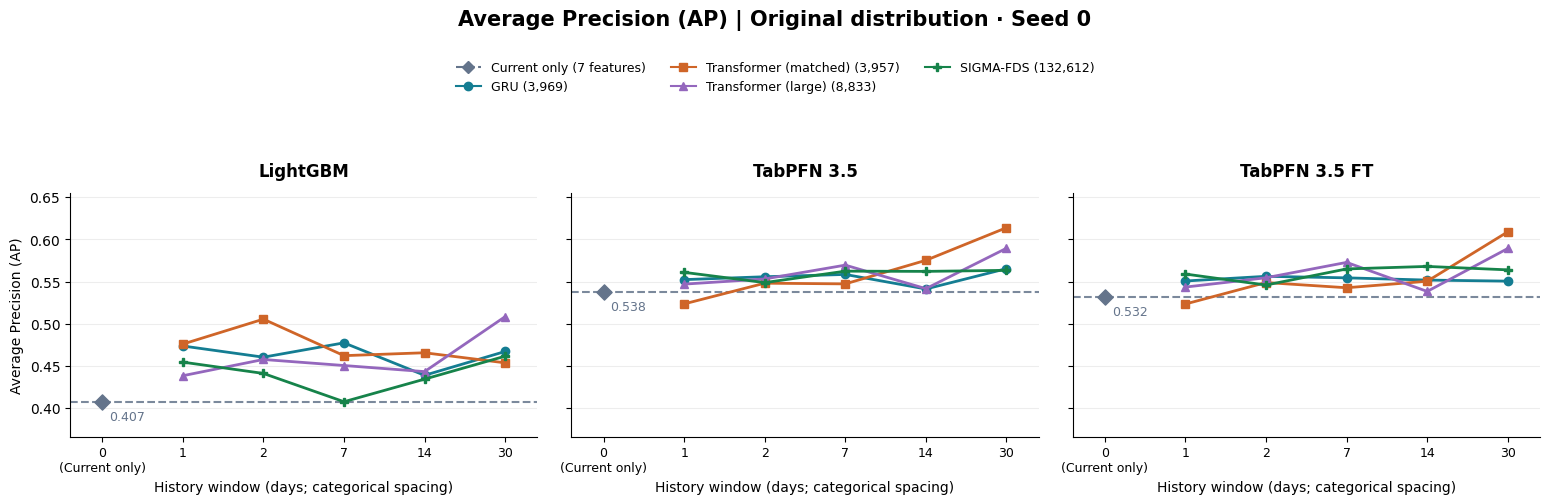

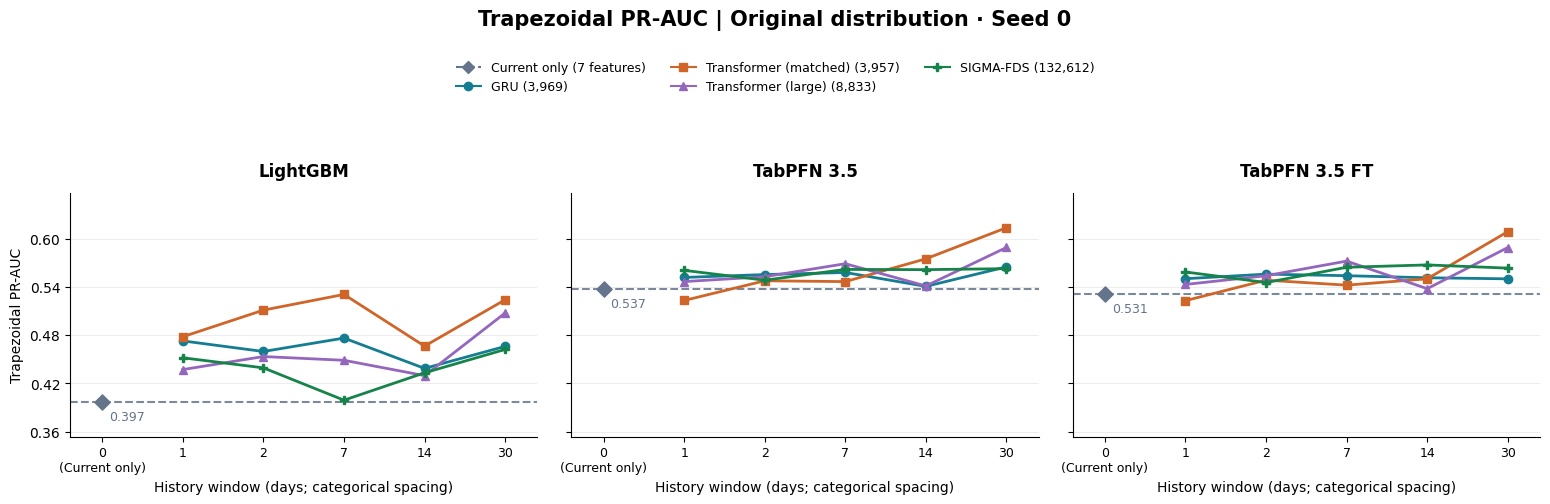

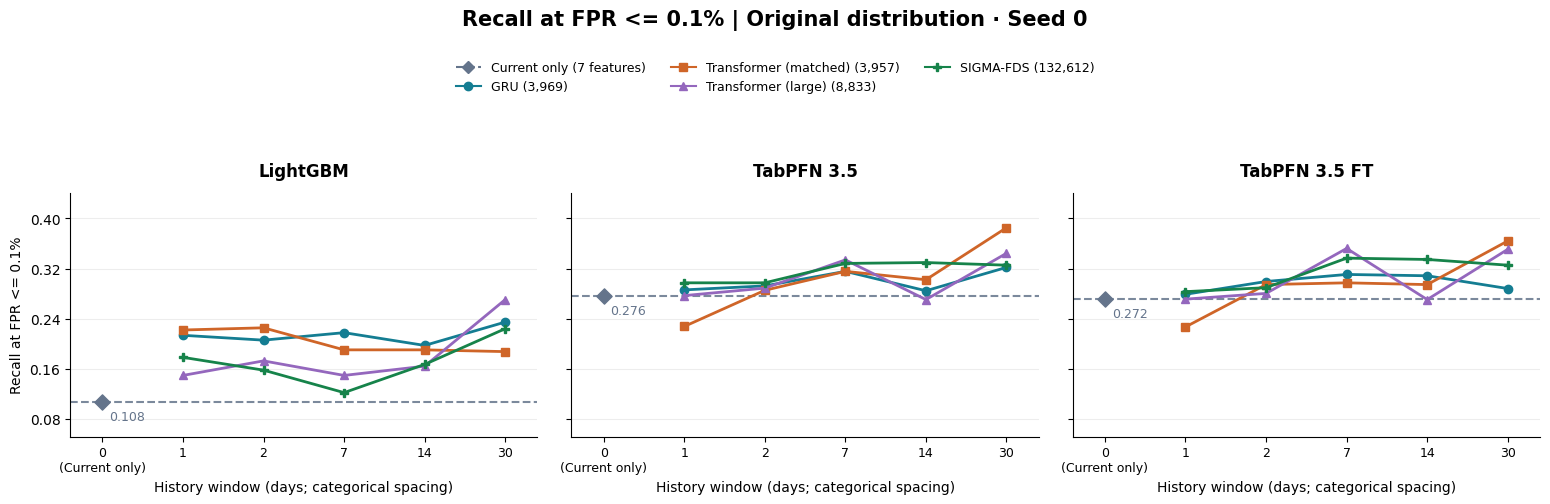

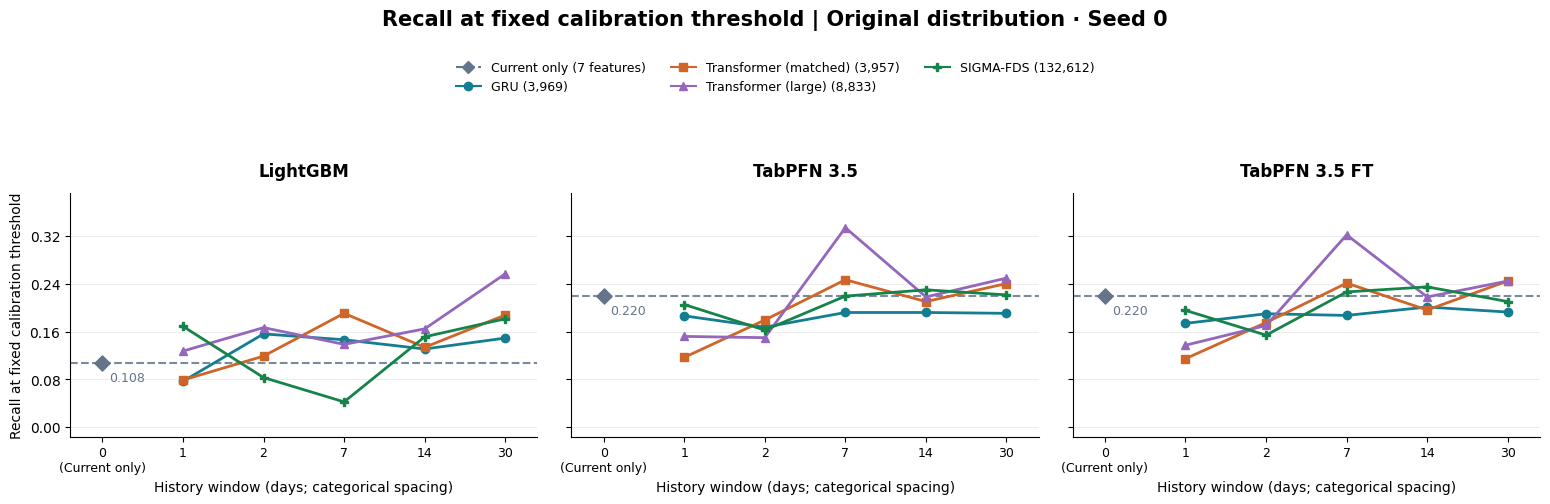

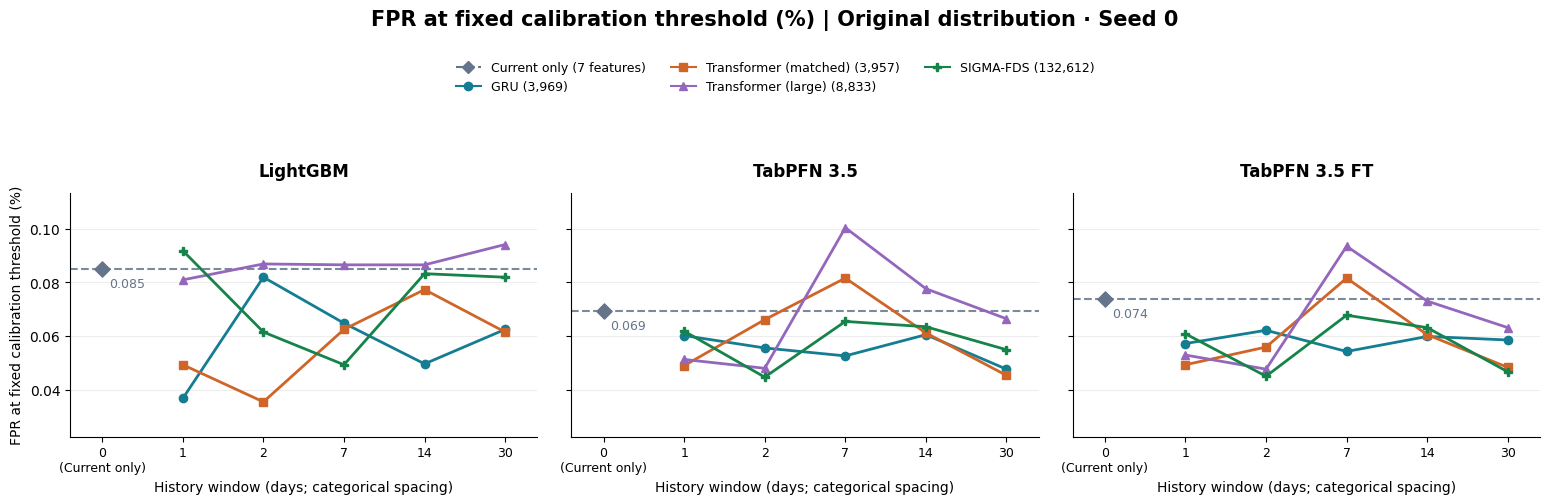

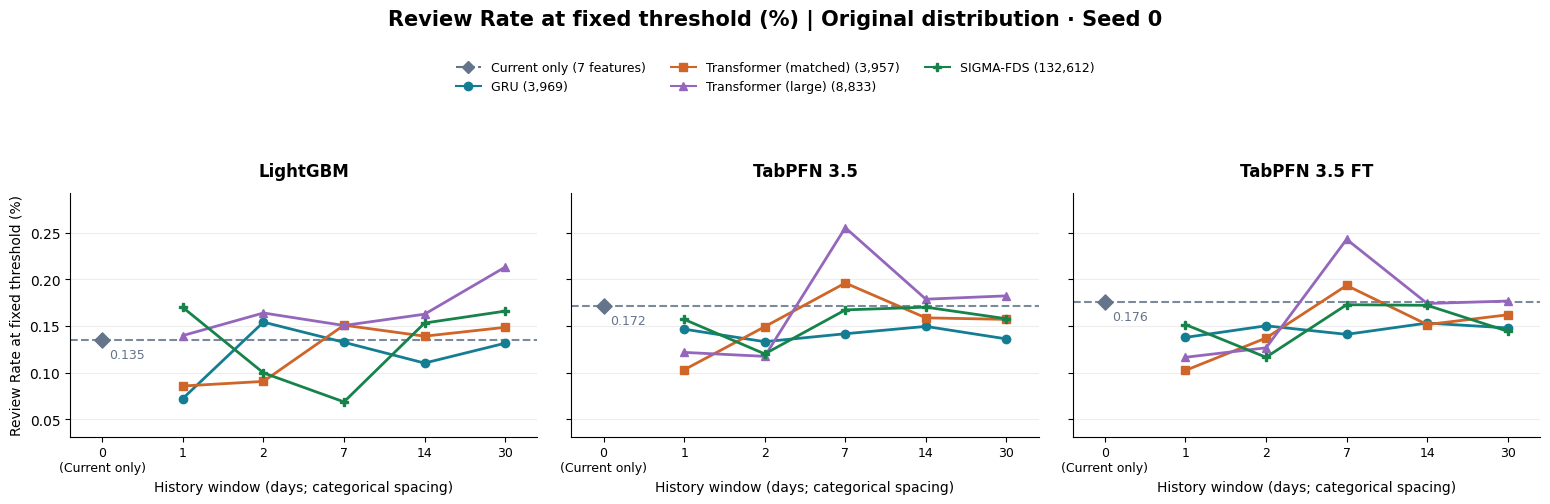

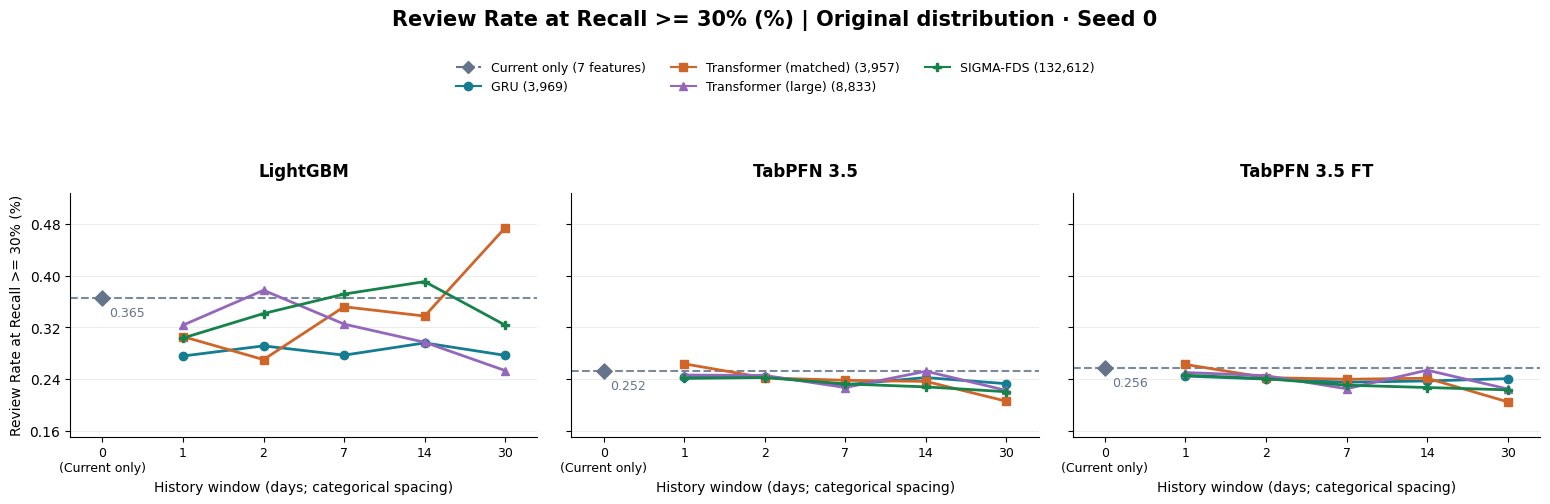

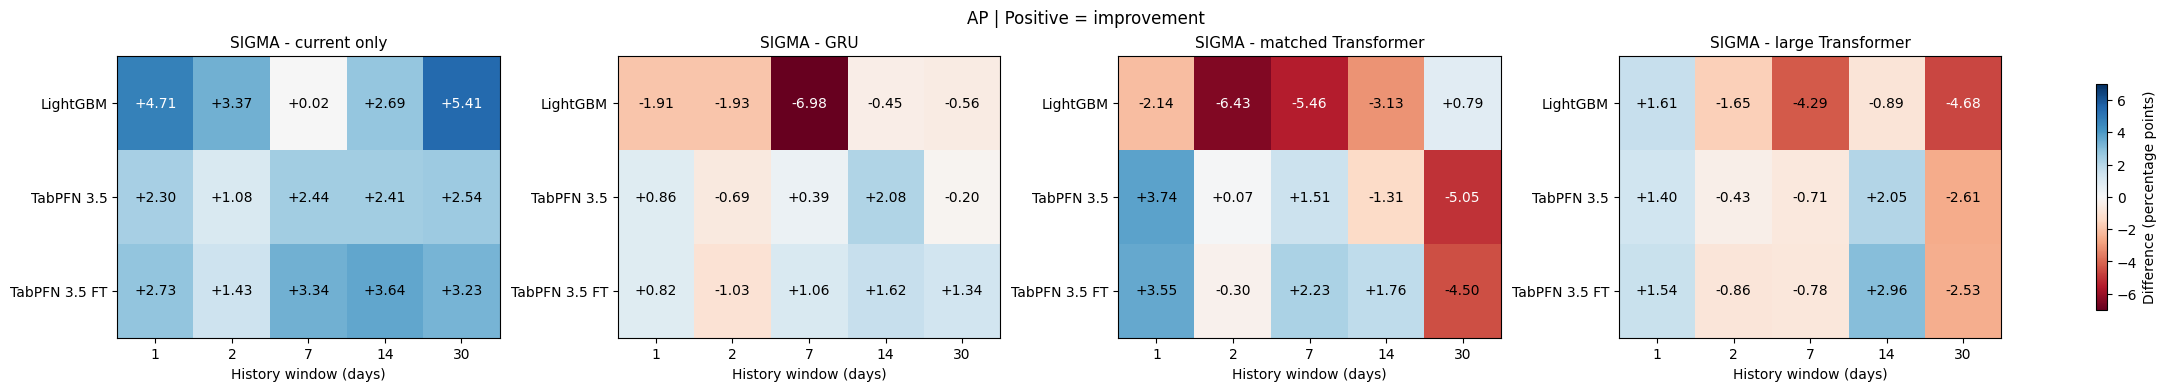

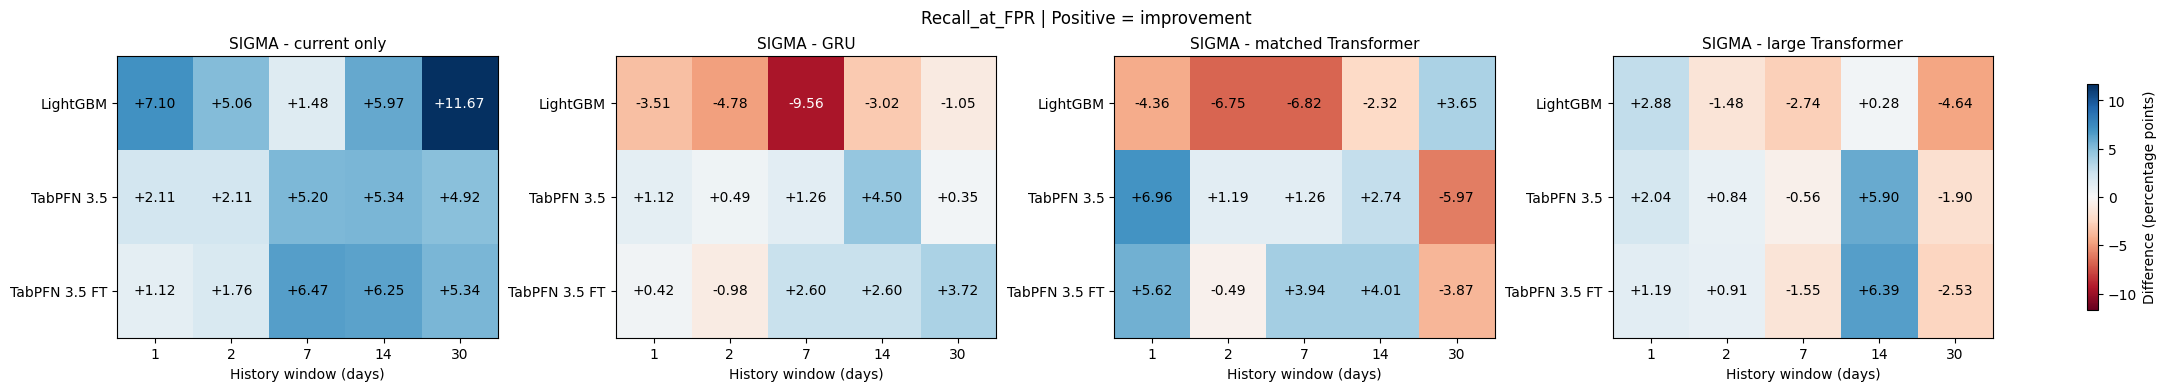

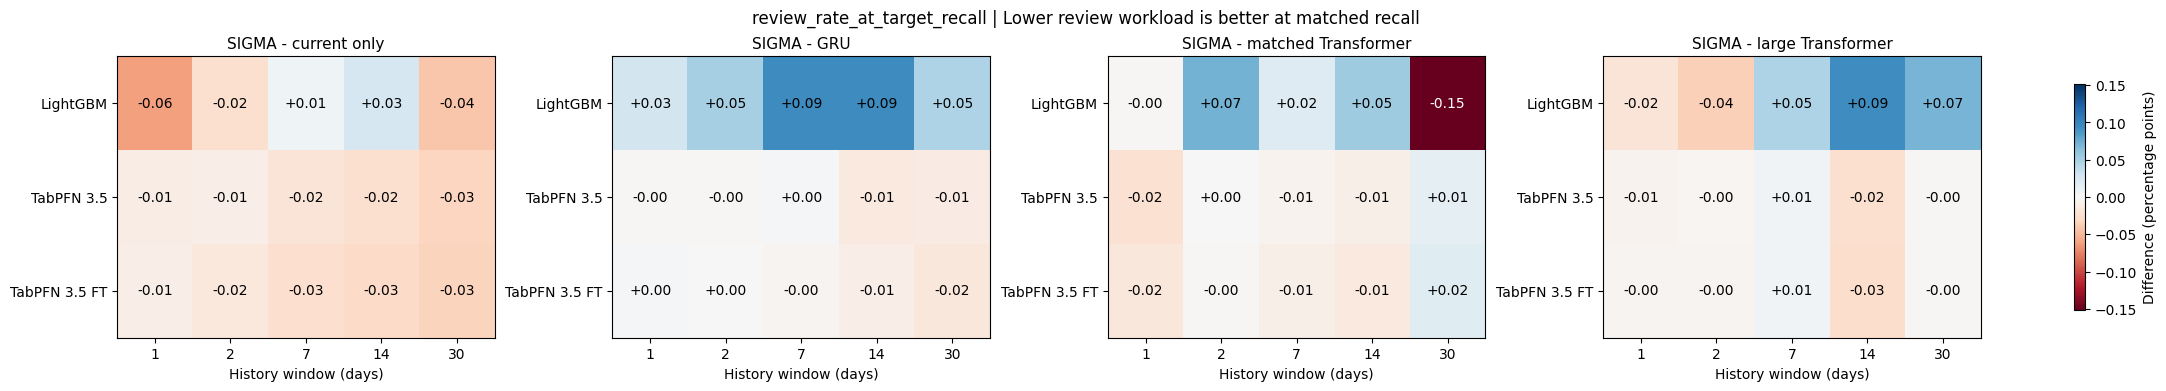

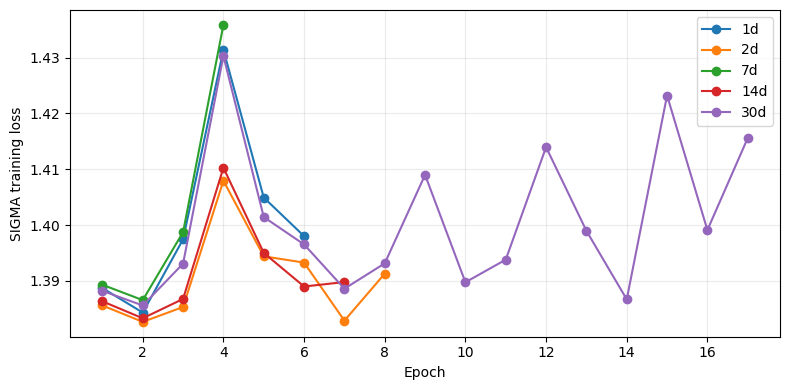

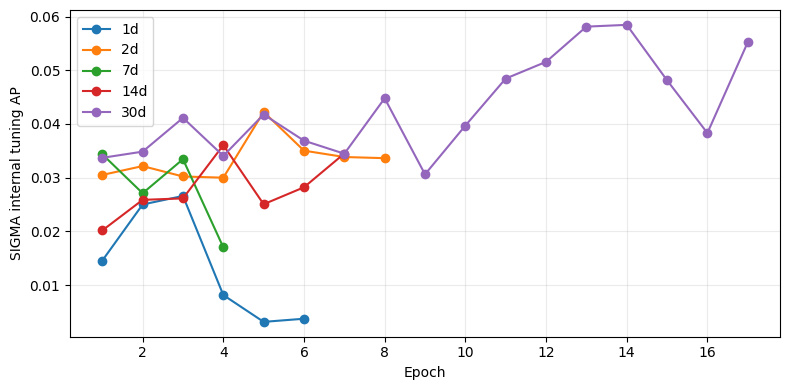

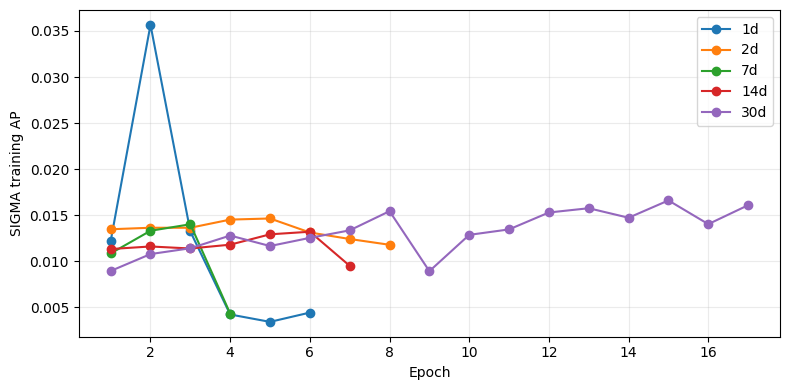

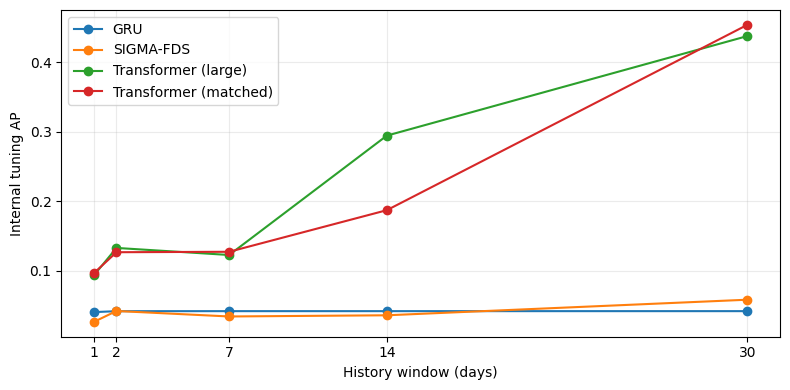

저장 경로: /content/drive/MyDrive/26-2_AI_project/processed/full/sigma_fds_native_width_torchscan_tabpfn35_original_seed0_v1_full/pilot_seed0
단일 seed 예비 실험. Test 미사용. Review Rate는 Recall/FPR과 함께 해석.


In [10]:
# 10. SIGMA-FDS vs current only, GRU, matched and optional large Transformer
res=collect()
assert not res.duplicated(['days','seed','model']).any()
assert len(res)==len(RUN_DAYS)*len(MODELS)*len(RUN_SEEDS), 'SIGMA 예비 실험 미완료'
res['encoder_train_sec']=res['sigma_train_sec']; res['encoder_tune_AP']=res['sigma_tune_AP']
write_csv(PILOT/'sigma_seed0.csv',res)
allres=pd.concat([reference,res],ignore_index=True).sort_values(['model','days','history_encoder'])
write_csv(PILOT/'comparison_all_encoders_seed0.csv',allres)
cols=['history_encoder','days','model','encoder_parameters','encoder_tune_AP','AP','PR_AUC','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed','review_rate_at_target_recall','p95_ms']
display(allres[cols].round(5))
metric_keys=['AP','PR_AUC','Recall_at_FPR','fixed_recall','fixed_fpr','review_rate_fixed','review_rate_at_target_recall']
base=reference[reference.days.eq(0)][['seed','model']+metric_keys].rename(columns={k:k+'_baseline' for k in metric_keys})
gru=reference[reference.history_encoder.eq('GRU')][['seed','days','model']+metric_keys].rename(columns={k:k+'_gru' for k in metric_keys})
paired=res.merge(base,on=['seed','model'],validate='many_to_one').merge(gru,on=['seed','days','model'],validate='one_to_one')
for k in metric_keys:
    paired[k+'_vs_baseline_pp']=100*(paired[k]-paired[k+'_baseline'])
    paired[k+'_vs_gru_pp']=100*(paired[k]-paired[k+'_gru'])
for enc,suffix in [('Transformer (matched)','matched'),('Transformer (large)','large')]:
    r=reference[reference.history_encoder.eq(enc)][['seed','days','model']+metric_keys]
    if len(r):
        paired=paired.merge(r.rename(columns={k:k+'_'+suffix for k in metric_keys}),on=['seed','days','model'],validate='one_to_one')
        for k in metric_keys: paired[k+'_vs_'+suffix+'_pp']=100*(paired[k]-paired[k+'_'+suffix])
write_csv(PILOT/'paired_sigma_vs_references_seed0.csv',paired)
display(paired[['days','model','AP_vs_baseline_pp','AP_vs_gru_pp','Recall_at_FPR_vs_gru_pp','review_rate_at_target_recall_vs_gru_pp']].sort_values(['model','days']).round(4))
# 모델별 3-way 비교: 0일 현재 거래만 사용을 명시하고 각 관찰 기간을 동일 간격 범주로 표시.
from matplotlib.ticker import MaxNLocator
from matplotlib.lines import Line2D
palette={'Current transaction only':'#64748b','GRU':'#147d92','Transformer (matched)':'#cf6528','Transformer (large)':'#9467bd','SIGMA-FDS':'#16834a'}
styles={'GRU':'o-','Transformer (matched)':'s-','Transformer (large)':'^-','SIGMA-FDS':'P-'}
styles={k:v for k,v in styles.items() if k in set(allres.history_encoder)}
windows=[0]+RUN_DAYS
positions={d:i for i,d in enumerate(windows)}
metric_specs=[('AP','Average Precision (AP)'),('PR_AUC','Trapezoidal PR-AUC'),('Recall_at_FPR','Recall at FPR <= 0.1%'),('fixed_recall','Recall at fixed calibration threshold'),('fixed_fpr','FPR at fixed calibration threshold (%)'),('review_rate_fixed','Review Rate at fixed threshold (%)'),('review_rate_at_target_recall','Review Rate at Recall >= 30% (%)')]
for k,title in metric_specs:
    fig,axes=plt.subplots(1,3,figsize=(15.6,5.1),sharey=True)
    factor=100 if k.startswith('review_rate_') or k=='fixed_fpr' else 1
    for ax,m in zip(axes,MODELS):
        b=allres[(allres.model==m)&(allres.history_encoder=='Current transaction only')]
        baseval=float(b[k].iloc[0])*factor
        ax.axhline(baseval,color=palette['Current transaction only'],ls='--',lw=1.5,alpha=.85)
        ax.scatter(0,baseval,marker='D',s=60,color=palette['Current transaction only'],zorder=5)
        ax.annotate(f'{baseval:.3f}',(0,baseval),xytext=(5,-13),textcoords='offset points',fontsize=9,color=palette['Current transaction only'])
        for enc,style in styles.items():
            g=allres[(allres.model==m)&(allres.history_encoder==enc)].sort_values('days')
            ax.plot([positions[d] for d in g.days],g[k]*factor,style,color=palette[enc],lw=2,ms=6,label=enc)
        ax.set_title(m,fontweight='bold',pad=12); ax.set_xticks(range(len(windows)),['0\n(Current only)']+[str(d) for d in RUN_DAYS],fontsize=9)
        ax.set_xlabel('History window (days; categorical spacing)'); ax.grid(axis='y',alpha=.22); ax.margins(x=.08,y=.20)
        ax.spines[['top','right']].set_visible(False); ax.yaxis.set_major_locator(MaxNLocator(6))
    axes[0].set_ylabel(title)
    counts={'GRU':3969,'Transformer (matched)':3957,'Transformer (large)':8833,'SIGMA-FDS':SIGMA_PARAMS}
    handles=[Line2D([0],[0],color=palette['Current transaction only'],ls='--',marker='D',label='Current only (7 features)')]+[Line2D([0],[0],color=palette[k],marker=v[0],label=f'{k} ({counts[k]:,})') for k,v in styles.items()]
    fig.suptitle(title+' | Original distribution · Seed 0',fontsize=15,fontweight='bold',y=.98)
    fig.legend(handles=handles,loc='upper center',bbox_to_anchor=(.5,.90),ncol=3,frameon=False,fontsize=9)
    fig.tight_layout(rect=[0,0,1,.78]); fig.savefig(PILOT/f'compare_{k}.png',dpi=220,bbox_inches='tight'); fig.savefig(PILOT/f'compare_{k}.svg',bbox_inches='tight'); plt.show(); plt.close(fig)
# 변화량 heatmap: matched Transformer - GRU / current-only, 각 칸은 percentage points.
for k in ['AP','Recall_at_FPR','review_rate_at_target_recall']:
    suffixes=['_vs_baseline_pp','_vs_gru_pp','_vs_matched_pp']+(['_vs_large_pp'] if len(large) else [])
    fig,axes=plt.subplots(1,len(suffixes),figsize=(5.4*len(suffixes),3.8),layout='constrained')
    matrices=[paired.pivot(index='model',columns='days',values=k+s).reindex(index=MODELS,columns=RUN_DAYS).to_numpy() for s in suffixes]
    lim=max(1e-6,max(float(np.max(np.abs(a))) for a in matrices))
    for ax,mat,title in zip(axes,matrices,['SIGMA - current only','SIGMA - GRU','SIGMA - matched Transformer']+(['SIGMA - large Transformer'] if len(large) else [])):
        im=ax.imshow(mat,cmap='RdBu',vmin=-lim,vmax=lim,aspect='auto')
        for i in range(len(MODELS)):
            for j in range(len(RUN_DAYS)):
                v=mat[i,j]; ax.text(j,i,f'{v:+.2f}',ha='center',va='center',color='white' if abs(v)>.65*lim else 'black',fontsize=10)
        ax.set_xticks(range(len(RUN_DAYS)),RUN_DAYS); ax.set_yticks(range(len(MODELS)),MODELS); ax.set_xlabel('History window (days)'); ax.set_title(title,fontsize=11)
    fig.colorbar(im,ax=axes.tolist(),label='Difference (percentage points)',shrink=.8)
    fig.suptitle(k+(' | Lower review workload is better at matched recall' if k.startswith('review_rate') else ' | Positive = improvement'))
    fig.savefig(PILOT/f'delta_{k}.png',dpi=220,bbox_inches='tight'); fig.savefig(PILOT/f'delta_{k}.svg',bbox_inches='tight'); plt.show(); plt.close(fig)
# 시간은 서로 다른 GPU/CPU에서 측정했을 수 있어 원본 값만 별도 저장하고 직접 우열을 주장하지 않는다.
write_csv(PILOT/'timing_with_hardware_seed0.csv',allres[[k for k in ['history_encoder','days','model','session','gpu','cpu','encoder_train_sec','embedding_sec','classifier_fit_sec','offline_eval_sec','calibration_sec','p95_ms','classifier_p95_ms'] if k in allres]])
# Transformer 학습 곡선 및 GRU와 동일한 내부 tuning AP 비교
hist=[]
for d in RUN_DAYS:
    info=json.loads((OUT/'embeddings'/f'd{d}_s0.json').read_text())
    hist.extend(dict(days=d,seed=0,**h) for h in info['history'])
h=pd.DataFrame(hist); write_csv(PILOT/'sigma_history_seed0.csv',h)
for k,title in [('loss','SIGMA training loss'),('tune_AP','SIGMA internal tuning AP'),('fit_AP','SIGMA training AP')]:
    fig,ax=plt.subplots(figsize=(8,4))
    for d,g in h.groupby('days'): ax.plot(g.epoch,g[k],marker='o',label=f'{d}d')
    ax.set_xlabel('Epoch'); ax.set_ylabel(title); ax.grid(alpha=.25); ax.legend(); fig.tight_layout(); fig.savefig(PILOT/f'sigma_{k}.png',dpi=180); plt.show(); plt.close(fig)
encs=allres[allres.days.gt(0)].drop_duplicates(['history_encoder','days','seed'])
fig,ax=plt.subplots(figsize=(8,4))
for enc,g in encs.groupby('history_encoder'):
    g=g.sort_values('days'); ax.plot(g.days,g.encoder_tune_AP,marker='o',label=enc)
ax.set_xticks(RUN_DAYS); ax.set_xlabel('History window (days)'); ax.set_ylabel('Internal tuning AP'); ax.legend(); ax.grid(alpha=.25); fig.tight_layout(); fig.savefig(PILOT/'compare_encoder_tune_AP.png',dpi=180); plt.show(); plt.close(fig)
print('저장 경로:',PILOT)
print('단일 seed 예비 실험. Test 미사용. Review Rate는 Recall/FPR과 함께 해석.')


## Interpretation and limitations
- SIGMA-FDS is a domain-adapted model, not an exact reproduction of recommendation metrics. Pure PyTorch scan implements Mamba-1 recurrence rather than its fused CUDA kernel; latency is not an official SIGMA speed benchmark.
- Official architecture dimensions are retained (64/32/4/2, one layer, dropout .2). Parameter count includes the supervised head and is descriptive only. The performance comparison is NOT parameter-controlled; capacity and regularization can contribute to differences. Matched GRU/Transformer remains a separate controlled experiment.
- Logical training batch 256 uses 32-row gradient accumulation; inference batch 128. This preserves weighting and optimizer step count, but dropout masks and rounding need not match a single large-batch forward.
- Preserve the upstream raw mixing coefficients and asymmetric second gate (uses h1 in sigmoid path); do not silently correct paper/code discrepancies. Preserve dropout .2 and original initialization. No Time2Vec, actual time gap, or new input feature.
- All past bins only, same unmasked padding convention and split as GRU/Transformers. Reverse branch cannot access current/future bins. Fixed last 5 bins (15h) preserved; proportion changes with window.
- Fit AP is diagnostic only, tune AP still controls checkpoint; same fit rows shared by encoder/classifier. Seed 0 only, independent test untouched. No causal claim or statistical superiority; additional seeds and ablation needed.
- A100 GPU smoke test must pass before training. Review rate must be read jointly with recall/FPR; diagnostic ROC thresholds not deployed thresholds. Timing across hardware/backends is not a fair speed comparison.
- Completed run files and checkpoints retained. Missing Large Transformer runs are not plotted; rerun comparison cell after completing them (rerun reference cell first). All source directories read-only except new SIGMA directory.
